# Pencils down analysis
Same as other connectome notebook, but with synapses filtered to the 85% confidence RoI: z extents 4027-5921. This filtering happens at the bottom of cell 2. 

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import csv
import pandas as pd
plt.rcParams['svg.fonttype'] = 'none'

In [4]:
start_checkpoint = 0
end_checkpoint = 45
filenames = [
    "connectome-0k-101625.csv",
    "connectome-5k-100725.csv",
    "connectome-10k-100725.csv",
    "connectome-15k-100725.csv",
    "connectome-20k-100725.csv",
    "connectome-25k-100725.csv",
    "connectome-30k-100725.csv",
    "connectome-35k-100725.csv",
    "connectome-40k-080625.csv",
    "connectome-45k-101625.csv"
]

def load_connectome(filename):

    # Load connectome data
    connectome_df = pd.read_csv(filename)

    # Parse the synapse_id column
    if filename == "connectome-40k-080625.csv":
        connectome_df[['type', 'x', 'y', 'z', 'pre', 'post', 'id']] = connectome_df['synapse_id'].str.split('_', expand=True)
    else:
        connectome_df[['type', 'x', 'y', 'z', 'pre', 'post']] = connectome_df['synapse_id'].str.split('_', expand=True)
    # Extract the numerical values
    connectome_df['x'] = connectome_df['x'].str.replace('x', '', regex=False)
    connectome_df['y'] = connectome_df['y'].str.replace('y', '', regex=False)
    connectome_df['z'] = connectome_df['z'].str.replace('z', '', regex=False)
    connectome_df['pre'] = connectome_df['pre'].str.replace('pre', '', regex=False)
    connectome_df['post'] = connectome_df['post'].str.replace('post', '', regex=False)
    if filename == "connectome-40k-080625.csv":
        connectome_df['id'] = connectome_df['id'].str.replace('id', '', regex=False)
        connectome_df[['x', 'y', 'z', 'pre', 'post', 'id']] = connectome_df[['x', 'y', 'z', 'pre', 'post', 'id']].apply(pd.to_numeric)
    else:
        connectome_df[['x', 'y', 'z', 'pre', 'post']] = connectome_df[['x', 'y', 'z', 'pre', 'post']].apply(pd.to_numeric)

    # Filter out any ids of -1
    connectome_df = connectome_df[connectome_df['pre'] != -1] 
    connectome_df = connectome_df[connectome_df['post'] != -1] 

    # These coords are in 36,36,42 so lets convert back to base res of 9,9,21
    connectome_df['x'] = connectome_df['x'] * 4
    connectome_df['y'] = connectome_df['y'] * 4
    connectome_df['z'] = connectome_df['z'] * 2

    connectome_df = connectome_df[connectome_df['z'] <= 5921]
    connectome_df = connectome_df[connectome_df['z'] >= 4027]

    return connectome_df


In [5]:
connectome_dfs = []
for filename in filenames:
    connectome_dfs.append(load_connectome(filename))

connectome_dfs[0]

,graph_id,synapse_id,type,x,y,z,pre,post
0,connectome-0k-101625,syn_x1000_y1093_z2152_pre37775021_post19204134,syn,4000,4372,4304,37775021,19204134
7,connectome-0k-101625,syn_x1001_y1390_z2128_pre24733411_post21979284,syn,4004,5560,4256,24733411,21979284
11,connectome-0k-101625,syn_x1002_y1026_z2858_pre32607496_post30009516,syn,4008,4104,5716,32607496,30009516
31,connectome-0k-101625,syn_x1006_y1088_z2142_pre37775021_post19204134,syn,4024,4352,4284,37775021,19204134
69,connectome-0k-101625,syn_x1015_y1118_z2104_pre22213782_post22219044,syn,4060,4472,4208,22213782,22219044
...,...,...,...,...,...,...,...,...
125557,connectome-0k-101625,syn_x993_y1130_z2089_pre22218795_post21875416,syn,3972,4520,4178,22218795,21875416
125565,connectome-0k-101625,syn_x993_y1891_z2462_pre27390732_post27515770,syn,3972,7564,4924,27390732,27515770
125579,connectome-0k-101625,syn_x996_y1034_z2856_pre32607496_post32487905,syn,3984,4136,5712,32607496,32487905
125583,connectome-0k-101625,syn_x997_y1136_z2089_pre22218795_post21973941,syn,3988,4544,4178,22218795,21973941


In [6]:
connectomes = []
for connectome in connectome_dfs:
    G = nx.from_pandas_edgelist(connectome, source='pre', target='post')
    connectomes.append(G)

In [24]:
original_edge_count = len(connectomes[0].edges())
original_node_count = len(connectomes[0].nodes())
connectome_edge_counts = [len(g.edges()) - original_edge_count for g in connectomes]
connectome_node_counts = [len(g.nodes()) - original_node_count for g in connectomes]
original_node_count

9019

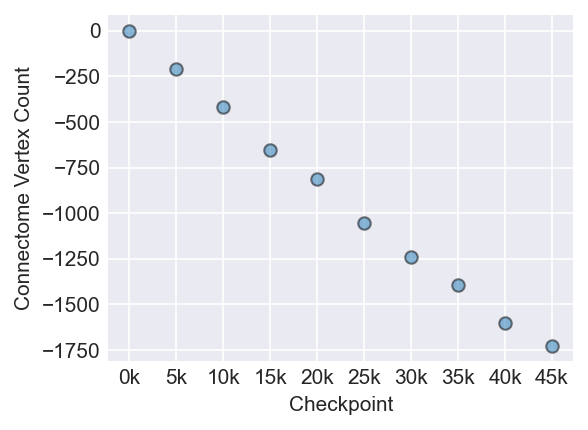

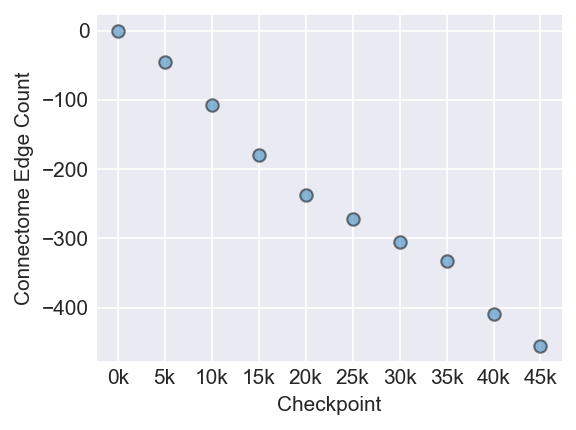

In [8]:
start_checkpoint = 0
end_checkpoint = 45
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [connectome_node_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Vertex Count")

    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [connectome_edge_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Edge Count")


    plt.show()

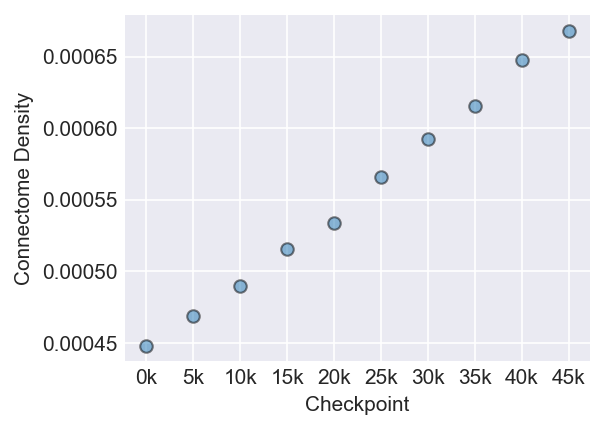

In [9]:
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [nx.density(g) for g in connectomes],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Density")
    plt.show()

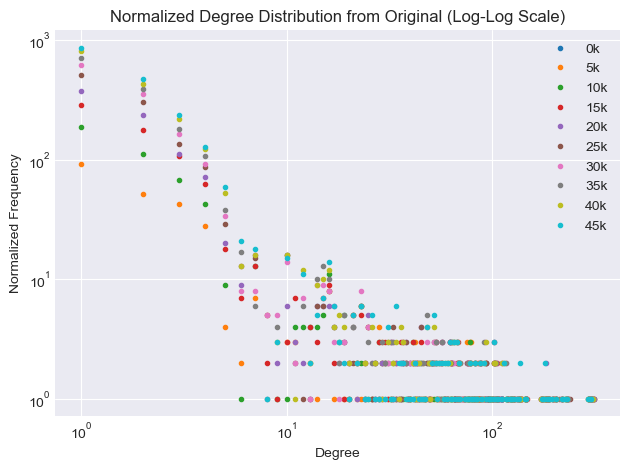

In [ ]:
def create_yaxis(original_degree_freq, degree_freq):
    orig_len = len(original_degree_freq)
    new_len = len(degree_freq)
    num_to_pad = abs(orig_len - new_len)
    if orig_len > new_len:
        degree_freq = np.pad(degree_freq, (0,num_to_pad), "constant", constant_values=0)
    elif new_len > orig_len:
        original_degree_freq = np.pad(original_degree_freq, (0,num_to_pad), "constant", constant_values=0)
    return abs(original_degree_freq - degree_freq)

original_degree_freq = np.array(nx.degree_histogram(connectomes[0]))
with plt.style.context("seaborn-v0_8-darkgrid"):
    # fig, axes = plt.subplots(2, 5, figsize=(16,9))
    plt.xlabel('Degree')
    plt.ylabel('Normalized Frequency')
    plt.title('Normalized Degree Distribution from Original (Log-Log Scale)')
    for i, contactome in enumerate(connectomes):
        degree_freq = np.array(nx.degree_histogram(contactome))
        yaxis = create_yaxis(original_degree_freq, degree_freq)
        xaxis = range(len(yaxis))
        plt.loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="3")
        plt.legend()
        # axes[0 if i < 5 else 1, i%5].loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].loglog(range(len(degree_freq)), degree_freq, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].legend()
    plt.tight_layout()
    plt.show()
    # Do lots of graphs with OG on each one with connected line sesgment

In [11]:
masterEM = pd.read_csv("MasterEM_10-29-25_45k_seg_ids.csv")
changes = pd.read_csv("changes.tsv", delimiter="\t", names=["change", "id1", "id2"])
changes

,change,id1,id2
0,+,667979,670152.0
1,+,670152,19219544.0
2,+,19219544,24495799.0
3,+,24495799,27250256.0
4,+,27250256,29878832.0
...,...,...,...
48695,+,35144741,35144812.0
48696,-,35144741,35144812.0
48697,+,35144755,35144862.0
48698,-,35144755,35144862.0


In [21]:
traced_status_df = masterEM[["seg_45k_id","Percent through"]].copy()
traced_status_df["edit_no_completed"] = -1

for index, row in changes.iterrows():
    # Access values from df1
    current_idx = index
    current_id1 = row['id1']
    current_id2 = row['id2']

    # Find corresponding row in df2 and update
    if current_id1 in traced_status_df['seg_45k_id'].values:
        traced_status_df.loc[traced_status_df['seg_45k_id'] == current_id1, 'edit_no_completed'] = current_idx
    if current_id2 in traced_status_df['seg_45k_id'].values:
        traced_status_df.loc[traced_status_df['seg_45k_id'] == current_id2, 'edit_no_completed'] = current_idx

traced_status_df = (
    traced_status_df.groupby("seg_45k_id", dropna=False)
        .agg({
            "Percent through": lambda s: "???" if '???' in list(s) or '<50%' in list(s) or '>50%' in list(s) else "100%",
            # "Percent through": lambda s: print(s),
            "edit_no_completed" : lambda s: s.max(skipna=True)
        })
        .reset_index()
)

traced_status_df

,seg_45k_id,Percent through,edit_no_completed
0,0,???,-1
1,444162,100%,31458
2,550518,100%,16863
3,554355,100%,16691
4,558647,100%,-1
...,...,...,...
2298,50896929,100%,16072
2299,53402525,100%,20855
2300,53516765,???,48472
2301,54675565,100%,12965


In [18]:
traced_counts = []
num_nodes = []
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)]
for i, connectome in enumerate(connectomes):
    node_list = list(connectome.nodes())
    num_nodes.append(len(node_list))
    node_df = pd.DataFrame({"seg_45k_id": node_list})
    node_df = node_df.merge(traced_status_df, on="seg_45k_id", how="left", validate="m:1")
    node_df = node_df[node_df['edit_no_completed'] <= checkpoint_nos[i]]
    traced_counts.append(node_df['Percent through'].value_counts()['100%'])
print(traced_counts)
print(num_nodes)

[np.int64(7), np.int64(106), np.int64(177), np.int64(246), np.int64(333), np.int64(427), np.int64(495), np.int64(554), np.int64(595), np.int64(629)]
[9019, 8806, 8602, 8365, 8208, 7967, 7779, 7623, 7419, 7293]


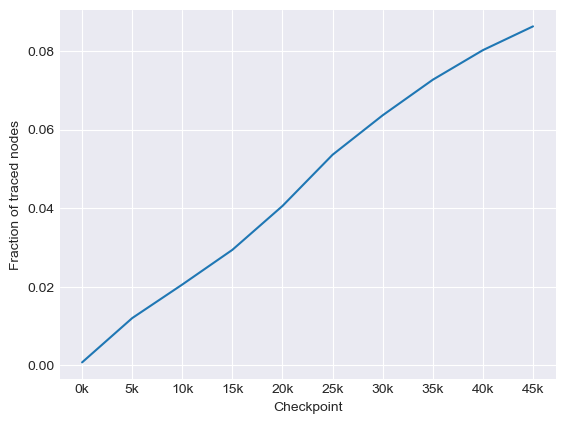

In [14]:
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)],
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.xlabel('Checkpoint')
    plt.ylabel('Fraction of traced nodes')
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(traced_counts) / np.array(num_nodes)
    )
    plt.show()

In [20]:
presynapse_completion = []
postsynapse_completion = []
both_completeness = []
either_completeness = []
num_synapses = []
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)]
for i, connectome_df in enumerate(connectome_dfs):
    pre_list = list(connectome_df["pre"])
    post_list = list(connectome_df["post"])
    num_synapses.append(len(connectome_df))

    pre_df = pd.DataFrame({"seg_45k_id": pre_list})
    pre_df = pre_df.merge(traced_status_df, on="seg_45k_id", how="left", validate="m:1")
    pre_df = pre_df[pre_df['edit_no_completed'] <= checkpoint_nos[i]]
    presynapse_completion.append(pre_df['Percent through'].value_counts()['100%'])

    post_df = pd.DataFrame({"seg_45k_id": post_list})
    post_df = post_df.merge(traced_status_df, on="seg_45k_id", how="left", validate="m:1")
    post_df = post_df[post_df['edit_no_completed'] <= checkpoint_nos[i]]
    postsynapse_completion.append(post_df['Percent through'].value_counts()['100%'])

presynapse_completion

[np.int64(56),
 np.int64(793),
 np.int64(1434),
 np.int64(2024),
 np.int64(2872),
 np.int64(3548),
 np.int64(4024),
 np.int64(4525),
 np.int64(5118),
 np.int64(5553)]

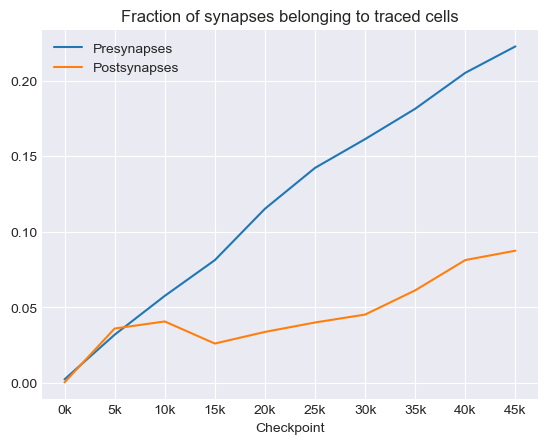

In [16]:
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)],
with plt.style.context("seaborn-v0_8-darkgrid"):
    # fig, axes = plt.subplots(2, 5, figsize=(16,9))
    plt.xlabel('Checkpoint')
    plt.title('Fraction of synapses belonging to traced cells')
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(presynapse_completion) / np.array(num_synapses),
        label="Presynapses"
    )
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(postsynapse_completion) / np.array(num_synapses),
        label="Postsynapses"
    )
    plt.legend()
    plt.show()

In [ ]:
# average degree (scalar)
# assortativity
# diameter
# average shortest path length
# betweenness centrality (average)
# largest eigenvalue of adjacency matrix
# triplet counts (undirected and directed) (Jordan can run)
# maybe modularity
# spectral gap